# 07 — Data quality: profiler, tests and incidents

**What you will learn:**
- The profiler: what it computes (table: row count, column count, size; column: nulls, distinct, unique, min/max), sampling (2.0 default is dynamic sampling; our YAML pins 100%) and its cost.
- Test definitions → test cases → test suites (the table's basic suite and logical suites), and the 25 built-in definitions grouped by level (table/column) and which data types each supports.
- Writing tests in YAML (the `TestSuite` workflow) and via API; custom SQL tests for anything else.
- Results over time, the failed-rows sample, and incidents (resolution status New → Ack → Assigned → Resolved).
- Traps: unsupported column types, `matchEnum`, `forceUpdate`, stale test cases, distinct vs unique.

This chapter is the data-quality stop of Level 3 of the tutorial tree ("each job in depth", see `plan.md`). It deepens the *trust* job from chapter 01, question 4: *how do I measure data, write checks that catch real defects, and follow a failure until it is fixed?* It builds on chapters 01 (four quality results seen once), 04 (workflow YAML, `just ingest <name> test`, workflow order) and 05 (REST reads, PUT create-or-update, delete).

The loop for this chapter, in three steps: 1) **profile** to see the numbers, 2) **test** to decide pass/fail, 3) **incident** to act — with an owner. Each section below names which step of the loop it zooms into.


In [1]:
import sys
from pathlib import Path

here = Path.cwd()
ROOT = next(d for d in [here, *here.parents, here / "project"] if (d / "pyproject.toml").exists() and (d / "src" / "openmetadata_tutorial").exists())
sys.path.insert(0, str(ROOT / "src"))

from openmetadata_tutorial import nb
ROOT = nb.setup()

import importlib
from openmetadata_tutorial import client, ch07_quality
ch07_quality = importlib.reload(ch07_quality)
Q = ch07_quality
print("project root:", ROOT)

project root: /Users/sergii/.ai/knowledge/tutorials/openmetadata/project


This zooms into step 1 of the loop — *seeing the numbers* — and answers: *what does `raw.orders` look like as statistics?* The profiler workflow (chapter 04 ran it) read every row and stored one table-level and one per-column summary. Table level first:

In [2]:
print(Q.table_summary(Q.ORDERS))

{'table': 'brightcup_pg.brightcup.raw.orders', 'rowCount': 1000.0, 'columnCount': 6.0, 'sizeInByte': 106496.0, 'sample_percent': 100.0, 'how': 'GET /v1/tables/<FQN>/tableProfile/latest'}


1,000 rows, 6 columns, about 104 KB, sampled at 100%. **What it means for us:** on our toy tables a full scan is free; on a billion-row fact table it is a warehouse bill and a slow query — sampling exists for that (last section). Now the per-column numbers:

In [3]:
Q.profile(Q.ORDERS)

,column,nullCount,distinctCount,uniqueCount,min,max
0,order_id,0.0,997.0,994.0,1,1000
1,customer_id,0.0,199.0,5.0,1,200
2,order_ts,0.0,1000.0,1000.0,2026-07-01T10:35:22,2026-09-30T22:07:37
3,status,0.0,6.0,0.0,6,9
4,total_amount,0.0,898.0,832.0,-143.61,279.54
5,currency,0.0,1.0,0.0,3,3


Read every row of that table — the planted defects (chapter 01 named them) stare back, plus three rows a reader will misread without the notes below:

- `order_id`: 1,000 values but only 997 *distinct* — 3 ids appear twice. *Distinct* counts values that differ; *unique* counts values that appear **exactly once**: each duplicated id kills two "appear once" slots, so unique is 1,000 − 2×3 = 994. The uniqueness test later says exactly that.
- `customer_id`: 199 distinct of the shop's 200 customers (the customers profile below shows 200) — one customer never ordered. Unique 5: five customers appear exactly once (the `just sql` check in the next cell lists them: 9, 38, 150, 188, 189).
- `order_ts`: 1,000 distinct and 1,000 unique — no two orders share a timestamp.
- `status`: 6 distinct values — the 5 valid ones plus the misspelled `shiped` (4 rows, counted in the next cell). For string columns `min`/`max` are **lengths in characters**, not values: shortest 6 (`placed`, `shiped`), longest 9 (`cancelled`, `delivered`). Unique 0: no status appears exactly once.
- `total_amount`: minimum −143.61 — negative euro amounts in a column that should never go below zero (5 rows, counted next).
- `currency`: 1 distinct, unique 0, min = max = 3 — every row is `EUR` (3 characters).

The profile ran at a 100% sample (the table summary above says so), so these counts are exact, not estimates. **What it means for us:** the profile already *shows* every defect; tests turn "look at this number" into pass/fail with history, which is what a team can put on a schedule.

> **Important:** The profiler reads the data, unlike metadata ingestion which reads only names and shapes.
> **What it means for us:** It needs a database login with SELECT (our `om_reader`), it adds load to the source, and on personal data it touches personal data.
> **Why it matters:** Grant it read access consciously and sample large tables — a full scan of a huge table costs time, money, and privacy.

In [4]:
print(Q.sql("select count(*) from raw.orders where total_amount < 0"))
print(Q.sql("select status, count(*) from raw.orders group by 1 order by 1"))
print(Q.sql("select customer_id, count(*) from raw.orders group by 1 having count(*) = 1 order by 1"))

count 
-------
     5
(1 row)


status   | count 
-----------+-------
 cancelled |    60
 delivered |   575
 placed    |    96
 returned  |    46
 shiped    |     4
 shipped   |   219
(6 rows)


customer_id | count 
-------------+-------
           9 |     1
          38 |     1
         150 |     1
         188 |     1
         189 |     1
(5 rows)


Three counts straight from the shop database (the same queries `just sql` runs): 5 negative amounts, 4 `shiped` rows among 6 statuses, 5 one-order customers — exactly the profile's −143.61, 6 distinct, and unique 5. The prose never cites a number these cells did not print.

This zooms into step 2 of the loop — *deciding pass/fail* — and answers: *which checks already guard `raw.orders`, and what did they say?* One check per planted defect, plus a row-count sanity check:

In [5]:
Q.results(Q.ORDERS)

,test,definition,status,message
0,orders_no_negative_amounts,tableCustomSQLQuery,Failed,Found 5 row(s). Test query is expected to return <= 0 ro...
1,orders_order_id_unique,columnValuesToBeUnique,Failed,Found valuesCount=1000 vs. uniqueCount=994. Both counts ...
2,orders_row_count_between,tableRowCountToBeBetween,Success,"Found rowCount=1000 vs. the expected min=500.0, max=500..."
3,orders_status_in_set,columnValuesToBeInSet,Failed,Found countInSet=996.


Four cases, matching the plan's defects table exactly: `orders_row_count_between` passes (1,000 rows is inside 500–5,000); `orders_order_id_unique` fails ("valuesCount=1000 vs. uniqueCount=994"); `orders_no_negative_amounts` fails ("Found 5 row(s)"); `orders_status_in_set` fails ("countInSet=996", i.e. 4 of 1,000 outside the set). **What it means for us:** each message quotes the numbers that decided it — a failure here is debuggable without opening the database. These four cases live in `project/ingestion/quality.yaml`, the `TestSuite` workflow chapter 04's order ran:

In [6]:
print((ROOT / "ingestion" / "quality.yaml").read_text())

# Data quality: four tests on raw.orders: a row-count check (passes) and one test
# per planted defect (duplicate ids, negative amounts, misspelled status; all fail). `just ingest quality test`. Results appear on the table's
# Data Observability tab and through the API (/v1/dataQuality/testCases).
source:
  type: TestSuite
  serviceName: brightcup_pg
  sourceConfig:
    config:
      type: TestSuite
      entityFullyQualifiedName: brightcup_pg.brightcup.raw.orders
processor:
  type: orm-test-runner
  config:
    forceUpdate: true  # update existing test cases when parameters in this file change
    testCases:
      - name: orders_row_count_between
        testDefinitionName: tableRowCountToBeBetween
        parameterValues:
          - name: minValue
            value: "500"
          - name: maxValue
            value: "5000"
      - name: orders_order_id_unique
        testDefinitionName: columnValuesToBeUnique
        columnName: order_id
      - name: orders_no_negative_amounts
   

Block by block: `source` says which workflow (`TestSuite`) and which table it guards (`entityFullyQualifiedName`); `processor: orm-test-runner` carries the cases, each naming its definition and parameters; `sink: metadata-rest` writes results back to the server; `workflowConfig` points at the server inside Docker. The suite these runs created is a *basic* suite — one per table, named `<table>.testSuite`. The catalog can also hold *logical* suites (`basic: false`): named bundles grouping cases across tables — the next cell lists every suite — including the logical `Data Contract - daily_revenue-contract` one (`basic: False`); same cases, different grouping. Two lines deserve a bookmark: `forceUpdate: true` (parameters in this file overwrite the catalog on every run) and `matchEnum: "true"` on the status test. Both will break something instructive below. Note the negative-amounts case: it is a `tableCustomSQLQuery` — "give me the bad rows; fail if there are more than 0" — because no built-in definition fit (next section says why).

Same level, one step wider: *what checks exist to choose from?* The catalog of test definitions:

In [7]:
Q.suites()

,suite,basic,description
0,brightcup_pg.brightcup.analytics.daily_revenue Test Suite,True,Test Suite created from YAML processor config file
1,brightcup_pg.brightcup.raw.customers Test Suite,True,Test Suite created from YAML processor config file
2,brightcup_pg.brightcup.raw.orders Test Suite,True,Test Suite created from YAML processor config file
3,brightcup_pg.brightcup.raw.products.testSuite,True,
4,Data Contract - daily_revenue-contract,False,Logical test suite for Data Contract: daily_revenue-cont...


In [8]:
defs = Q.definitions()
print("definitions:", len(defs))
defs.assign(supportedDataTypes=defs["supportedDataTypes"].str.slice(0, 72))

definitions: 25


,name,entityType,supportedDataTypes
0,columnValueLengthsToBeBetween,COLUMN,"BYTES, STRING, MEDIUMTEXT, TEXT, CHAR, VARCHAR, ARRAY, L..."
1,columnValueMaxToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."
2,columnValueMeanToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."
3,columnValueMedianToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."
4,columnValueMinToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."
5,columnValueStdDevToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."
6,columnValuesMissingCount,COLUMN,"NUMBER, TINYINT, SMALLINT, INT, BIGINT, BYTEINT, BYTES, ..."
7,columnValuesSumToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."
8,columnValuesToBeAtExpectedLocation,COLUMN,"BYTES, STRING, MEDIUMTEXT, TEXT, CHAR, VARCHAR, NUMBER, ..."
9,columnValuesToBeBetween,COLUMN,"NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, ..."


In [9]:
print(defs.loc[defs["name"] == "columnValuesToBeBetween", "supportedDataTypes"].iloc[0])

NUMBER, INT, FLOAT, DOUBLE, DECIMAL, TINYINT, SMALLINT, BIGINT, BYTEINT, TIMESTAMP, TIMESTAMPZ, DATETIME, DATE


25 definitions: 9 table-level (names starting `table…`, no data types — they see whole tables) and 16 column-level (names starting `column…`, each with a supported-types list). The printed line is the full type list of `columnValuesToBeBetween`: NUMBER, INT, FLOAT, DOUBLE, DECIMAL, … — but no NUMERIC. Our `total_amount` is Postgres `NUMERIC`, so a "between 0 and 100000" test on it has no supported definition in 2.0.5 — that is exactly why the designer wrote the negative-amounts check as custom SQL instead.

> **Important:** Check `supportedDataTypes` before choosing a test; unsupported types fail at run time or are skipped.
> **What it means for us:** `columnValuesToBeBetween` on Postgres NUMERIC is one such gap in 2.0.5 — read the catalogue row first, write the test second.
> **Why it matters:** A test that cannot run on your column type is worse than no test: it looks like coverage and measures nothing. `tableCustomSQLQuery` covers anything else.

Medium step: *the same idea on another table.* `raw.customers` has 12 planted NULL emails. We add three cases in `project/ingestion/ch07_customers_quality.yaml` (same `TestSuite` shape as `quality.yaml`: not-null and unique on `email`, in-set on `country`), and run it from here exactly the way chapter 04 runs workflows — the CLI inside the ingestion container. The helper tails the run's own log, so the success line below is the workflow's, not ours:

In [10]:
yaml_path = ROOT / "ingestion" / "ch07_customers_quality.yaml"
FINAL_YAML = yaml_path.read_text()  # the good state; trap cells below restore it
print("cases in file:", FINAL_YAML.count("- name: customers_"))
print(Q.run_workflow())

cases in file: 3


[2026-10-12 12:38:38] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:38:38] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:38:38] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:38:38] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:38:38] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:38:38] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 1s 102.155ms


In [11]:
Q.results(Q.CUSTOMERS)

,test,definition,status,message
0,customers_country_in_set,columnValuesToBeInSet,Failed,Found countInSet=148.
1,customers_email_not_null,columnValuesToBeNotNull,Failed,Found nullCount=12. It should be 0
2,customers_email_unique,columnValuesToBeUnique,Success,Found valuesCount=188 vs. uniqueCount=188. Both counts s...


In [12]:
Q.profile(Q.CUSTOMERS)

,column,nullCount,distinctCount,uniqueCount,min,max
0,customer_id,0.0,200.0,200.0,1,200
1,full_name,0.0,130.0,75.0,8,17
2,email,12.0,188.0,188.0,21,32
3,phone,0.0,200.0,200.0,14,14
4,country,0.0,8.0,0.0,2,2
5,signup_date,0.0,158.0,125.0,2025-07-01,2026-07-01


In [13]:
print(Q.sql("select country, count(*) from raw.customers group by 1 order by 1"))
print(Q.sql("select count(*) from raw.customers where email is null"))

country | count 
---------+-------
 DE      |    18
 ES      |    24
 FR      |    24
 IT      |    29
 NL      |    23
 PL      |    30
 SE      |    24
 UA      |    28
(8 rows)


count 
-------
    12
(1 row)


Three cases, two red — every number below comes from the three outputs above:

- `customers_email_not_null` fails with "nullCount=12": the 12 planted NULLs, to the row — the profile's `email` row says null 12, and the `just sql` count says 12.
- `customers_email_unique` *passes*: "valuesCount=188 vs. uniqueCount=188" — it counted only the 188 non-null emails (200 − 12), all different; the profile row already told that story (distinct 188, unique 188). **What it means for us:** the uniqueness check ignores NULLs, so "unique" alone does not mean "complete" — the not-null + unique pair is the actual completeness check.
- `customers_country_in_set` fails with "countInSet=148": our set lists 6 of the 8 real countries (DE, FR, NL, PL, ES, IT — the country table above shows all 8), so 52 rows fall outside: 24 SE + 28 UA, per the same table.

Trap 1, shown not told. `columnValuesToBeInSet` takes an `allowedValues` list — and, by default, a second flag `matchEnum` set to `"false"`. Watch what happens when we drop the two `matchEnum` lines from the YAML and re-run: the same 52 out-of-set rows, the same message:

In [14]:
text = yaml_path.read_text().replace('          - name: matchEnum\n            value: "true"\n', "")
assert "name: matchEnum" not in text
yaml_path.write_text(text)
print(Q.run_workflow())
Q.results(Q.CUSTOMERS)[["test", "status", "message"]]

[2026-10-12 12:38:44] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:38:44] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:38:44] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:38:44] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:38:44] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:38:44] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 1s 126.164ms


,test,status,message
0,customers_country_in_set,Success,Found countInSet=148.
1,customers_email_not_null,Failed,Found nullCount=12. It should be 0
2,customers_email_unique,Success,Found valuesCount=188 vs. uniqueCount=188. Both counts s...


"Found countInSet=148" — and status **Success**. 52 rows outside the allowed set, green test. Compare with the run before: identical message, opposite verdict. Without `matchEnum` the same count (148) yields Success instead of Failed: with 52 rows outside the allowed set, the test still passed. That is the observed behavior on this run — whatever the default check computes internally, it did not fail on out-of-set rows.

> **Important:** `columnValuesToBeInSet` only fails on values outside the set when `matchEnum: "true"`.
> **What it means for us:** Without it the test can never fail on bad rows — the orders status test in `quality.yaml` carries the flag for exactly this reason.
> **Why it matters:** A test that can never fail gives false comfort: the dashboard stays green while misspelled statuses flow downstream.

Restore the flag, re-run, red again:

In [15]:
yaml_path.write_text(FINAL_YAML)
print(Q.run_workflow())
print(Q.results(Q.CUSTOMERS)[["test", "status"]].to_string())

[2026-10-12 12:38:49] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:38:49] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:38:49] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:38:49] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:38:49] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:38:49] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 757.281ms
                       test   status
0  customers_country_in_set   Failed
1  customers_email_not_null   Failed
2    customers_email_unique  Success


Trap 2: *who wins when the file and the catalog disagree?* Change the allowed set to two countries AND flip `forceUpdate` to `false`, then re-run. If the file were the source of truth, the catalog would now hold the 2-value set:

In [16]:
yaml_path.write_text(FINAL_YAML
                     .replace("forceUpdate: true", "forceUpdate: false")
                     .replace('["DE", "FR", "NL", "PL", "ES", "IT"]', '["DE", "FR"]'))
print(Q.run_workflow())
params = Q.yaml_case_params("ch07_customers_quality.yaml", "customers_country_in_set")
print("file says:      ", params["params"]["allowedValues"], "| forceUpdate:", params["forceUpdate"])
print("catalogue says: ", Q.test_case("customers_country_in_set")["parameterValues"][0]["value"])
print(Q.results(Q.CUSTOMERS)[["test", "status", "message"]].to_string())

[2026-10-12 12:38:54] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:38:54] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:38:54] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:38:54] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:38:54] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:38:54] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 792.995ms
file says:       ["DE", "FR"] | forceUpdate: False
catalogue says:  ["DE", "FR", "NL", "PL", "ES", "IT"]


                       test   status                                                                                                 message
0  customers_country_in_set   Failed                                                                                   Found countInSet=148.
1  customers_email_not_null   Failed                                                                      Found nullCount=12. It should be 0
2    customers_email_unique  Success  Found valuesCount=188 vs. uniqueCount=188. Both counts should be equal for column values to be unique.


The file says two countries (read back from the YAML by the cell above, not typed here); the catalog still holds six. With `forceUpdate: false` the runner creates missing cases but leaves existing parameters untouched — the run above even re-tested with the *old* set (still Failed on 148). **What it means for us:** after any parameter edit, check the catalog, not the file — or just keep `forceUpdate: true` as both shared YAMLs do.

Trap 3 is the same lesson from the other side. Restore the good file *plus* a throwaway row-count case with deliberately failing bounds (0–100 for a 200-row table), and run. Restoring with `forceUpdate: true` also proves the previous trap's fix: the catalog picks the 6-value set back up. The throwaway is deleted first so its history starts fresh however often this notebook re-runs:

In [17]:
Q.ensure_deleted("ch07_row_count_demo")
DEMO_FAIL = '''      - name: ch07_row_count_demo
        testDefinitionName: tableRowCountToBeBetween
        parameterValues:
          - name: minValue
            value: "0"
          - name: maxValue
            value: "100"
'''
assert "      - name: customers_email_not_null" in FINAL_YAML
yaml_path.write_text(FINAL_YAML.replace(
    "      - name: customers_email_not_null", DEMO_FAIL + "      - name: customers_email_not_null"))
print(Q.run_workflow())
print("catalogue set again:", Q.test_case("customers_country_in_set")["parameterValues"][0]["value"])
print(Q.results(Q.CUSTOMERS)[["test", "status"]].to_string())

[2026-10-12 12:39:02] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:39:02] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:39:02] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:39:02] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:39:02] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:39:02] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 2s 351.898ms
catalogue set again: ["DE", "FR", "NL", "PL", "ES", "IT"]
                       test   status
0       ch07_row_count_demo   Failed
1  customers_country_in_set   Failed
2  customers_email_not_null   Failed
3    customers_email_unique  Success


The 6-value set is back in the catalog, and the demo case fails as designed ("rowCount=200 vs. 0–100"). Now flip its bounds to 100–500 and run again — the red-to-green moment:

In [18]:
yaml_path.write_text(yaml_path.read_text()
                     .replace('value: "0"\n          - name: maxValue\n            value: "100"',
                              'value: "100"\n          - name: maxValue\n            value: "500"'))
print(Q.run_workflow())
DEMO_FQN = "brightcup_pg.brightcup.raw.customers.ch07_row_count_demo"
h = Q.history(DEMO_FQN)
assert len(h) == 2, len(h)
print("history points total:", len(h))
print(h.tail(3)[["timestamp", "status", "message"]].to_string())

[2026-10-12 12:39:09] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:39:09] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:39:09] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:39:09] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:39:09] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:39:09] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 1s 566.563ms
history points total: 2
                timestamp   status                                                     message
0 2026-10-12 12:39:00.804   Failed    Found rowCount=200 vs. the expected min=0.0,  max=100.0.
1 2026-10-12 12:39:09.529  Success  Found rowCount=200 vs. the expected min=100.0,  max=500.0.


Two points — Failed, then Success — same table, same data, only the bounds changed, and the assert above pins the count at exactly 2 (the demo case was deleted before this run, so these two points are its whole history). Two things to carry from this: first, in real life the green point comes from *fixing the source*, not loosening bounds (our planted defects stay broken on purpose — later chapters and the plan's defects table rely on them; the demo only moves bounds to show what a green point looks like). Second, history is the reason tests beat one-off profiles: every run appends a timestamped verdict. The removal run in the next cell appends a third Success, which is trap 3: remove the demo from the YAML entirely, confirm the file is back to its final state, and run once more:

In [19]:
text = yaml_path.read_text()
demo_block = '''      - name: ch07_row_count_demo
        testDefinitionName: tableRowCountToBeBetween
        parameterValues:
          - name: minValue
            value: "100"
          - name: maxValue
            value: "500"
'''
assert demo_block in text
yaml_path.write_text(text.replace(demo_block, ""))
assert yaml_path.read_text() == FINAL_YAML, "YAML is not back to its final state"
n_before = len(Q.history(DEMO_FQN))
assert n_before == 2, n_before
print(Q.run_workflow())
h = Q.history(DEMO_FQN)
assert len(h) == n_before + 1, len(h)
print("history points before/after the removal run:", n_before, "->", len(h))
print(h.tail(1)[["timestamp", "status"]].to_string())

[2026-10-12 12:39:16] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:39:16] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:39:16] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:39:16] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:39:16] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:39:16] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 762.252ms
history points before/after the removal run: 2 -> 3
                timestamp   status
2 2026-10-12 12:39:15.803  Success


Before → after grew by exactly one (asserted, not eyeballed): the suite ran the demo case *after* we deleted it from the file (the newest point carries the removal run's timestamp). Removing a test from YAML does not delete it from the catalog — the basic suite keeps running it with its last parameters. The only way to really remove it is the API, by id (chapter 05's hard delete):

> **Important:** The YAML is not the source of truth for test cases; the catalog is.
> **What it means for us:** Removed tests keep running, and changed parameters need `forceUpdate: true` — otherwise code review shows one thing and the schedule runs another.
> **Why it matters:** Drift between the file and the catalog is silent: green runs of a test nobody remembers writing, or parameters nobody remembers setting.

In [20]:
Q.delete_test_case(Q.test_case("ch07_row_count_demo")["id"])
print("remaining cases:", Q.results(Q.CUSTOMERS)["test"].tolist())
print("traces of ch07_row_count_demo:", Q.deleted_case_traces(DEMO_FQN))

remaining cases: ['customers_country_in_set', 'customers_email_not_null', 'customers_email_unique']
traces of ch07_row_count_demo: {'history': 'gone (404: no points)', 'incident_rows': 0}


Back to the final three (`customers_email_not_null`, `customers_email_unique`, `customers_country_in_set` with `matchEnum`), and the throwaway is gone from the catalog — the cell above shows its traces are gone too (history answers 404, zero incident rows).

Same level, one step wider: *writing a test without YAML.* The suite YAML is one door; `POST /v1/dataQuality/testCases` is the other — it takes the test case name, the table or column as an entity link, and the test *definition name* as a string (an EntityReference id answers 400 in 2.0.5 — found by trying). The new case joins the table's basic suite, so the next workflow run executes it. We add a sampled not-null check on `email`: same 12 NULLs, but created with row-count computation so each result carries passed/failed row counts and a failed-rows sample:

In [21]:
Q.ensure_deleted("ch07_email_sampled")
created = Q.create_test_case(
    "ch07_email_sampled",
    "<#E::table::brightcup_pg.brightcup.raw.customers::columns::email>",
    "columnValuesToBeNotNull",
    compute_rows=True,
)
print(created)
print(Q.run_workflow())

{'id': '4611e252-2e95-4a38-a7a3-14a23897e61c', 'name': 'ch07_email_sampled', 'fullyQualifiedName': 'brightcup_pg.brightcup.raw.customers.email.ch07_email_sampled'}


[2026-10-12 12:39:23] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:39:23] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:39:23] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:39:23] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:39:23] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:39:23] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 1s 742.710ms


In [22]:
SAMPLED_FQN = "brightcup_pg.brightcup.raw.customers.email.ch07_email_sampled"
h = Q.history(SAMPLED_FQN)
assert len(h) >= 1 and (h["failedRows"] == 12).all(), h.to_string()
print(h[["timestamp", "status", "failedRows", "message"]].to_string())

                timestamp  status  failedRows                             message
0 2026-10-12 12:39:22.510  Failed          12  Found nullCount=12. It should be 0


Failed with `failedRows=12` — compare with the YAML-written not-null case, whose history column is empty: that definition reports the 12 only inside its message, while this API-created case counted rows because it asked for row computation. **What it means for us:** `failedRows` is opt-in per test case; turn it on when you want counts over time (next section plots exactly this column) and the sample below. The sample is real failing rows:

In [23]:
print(Q.failed_rows_sample(created["id"]).to_string())

   customer_id         full_name email           phone country signup_date
0           10  Chloe Shevchenko  None  +49 30 5918715      ES  2025-08-14
1           82       Mila Garcia  None  +49 30 5674183      UA  2026-05-27
2           85       Ben Schmidt  None  +49 30 8290770      ES  2026-01-06
3           98    Jonas Kowalski  None  +49 30 4340845      DE  2026-04-17
4          125       Yuri Dubois  None  +49 30 5002120      SE  2026-04-28


Five of the twelve NULL-email rows — real customer ids, names and phones with the email column empty. That is the failed-rows sample: not a count but the evidence, one row per failure. The throwaway served its purpose; delete it, check its history and incident rows went with it, and confirm the final three:

In [24]:
Q.delete_test_case(created["id"])
remaining = Q.results(Q.CUSTOMERS)["test"].tolist()
assert remaining == ["customers_country_in_set", "customers_email_not_null", "customers_email_unique"], remaining
print("remaining cases:", remaining)
print("traces of ch07_email_sampled:", Q.deleted_case_traces(SAMPLED_FQN))

remaining cases: ['customers_country_in_set', 'customers_email_not_null', 'customers_email_unique']
traces of ch07_email_sampled: {'history': 'gone (404: no points)', 'incident_rows': 0}


This zooms into step 2's time axis — *what did the last week of runs say?* Every result above appended one timestamped row; summarize them for the not-null case — counts per status plus the last few runs; the plot right after draws exactly these points:

In [25]:
EMAIL_FQN = "brightcup_pg.brightcup.raw.customers.email.customers_email_not_null"
counts, recent = Q.history_trend(EMAIL_FQN)
print(counts.to_string(index=False))
print(recent[["timestamp", "status", "message"]].to_string(index=False))
print("distinct messages:", Q.history(EMAIL_FQN)["message"].unique().tolist())

status  runs
Failed   130
              timestamp status                            message
2026-10-12 12:38:54.596 Failed Found nullCount=12. It should be 0
2026-10-12 12:39:00.776 Failed Found nullCount=12. It should be 0
2026-10-12 12:39:09.497 Failed Found nullCount=12. It should be 0
2026-10-12 12:39:15.841 Failed Found nullCount=12. It should be 0
2026-10-12 12:39:22.594 Failed Found nullCount=12. It should be 0
distinct messages: ['Found nullCount=12. It should be 0']


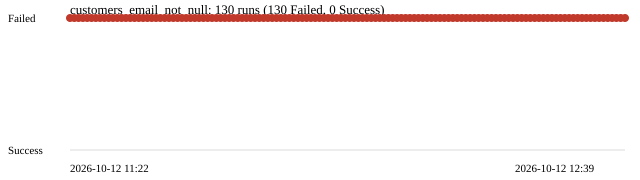

dots drawn: 130


In [26]:
from IPython.display import SVG, display
svg = Q.status_plot_svg(EMAIL_FQN)
display(SVG(data=svg))
print("dots drawn:", svg.count("<circle"))

Every run Failed with a single distinct message ("Found nullCount=12…") — the same 12 NULL emails, never fixed, never flaky. **What it means for us:** history separates "broken once" from "broken always": a single Failed could be a late feed, a solid wall of identical Failures is a source bug. Note where the 12 lives here: in the message, with an empty `failedRows` column (only row-computed cases like the API one above fill it — which is why the helper keeps the column but this table leaves it out). The plot above draws that wall: one dot per run, oldest first — every dot on the Failed line (no chart library ships with this project, so a dependency-free SVG from the helper draws it; its dot count matches the counts table exactly).

Complex step: *from failure to incident.* A failed test opens an incident — the same failure with an owner and a state. The transition list only grows, so read one row per test case as its current state — the reproducible view, the same on a fresh stack as here:

In [27]:
print(Q.current_incidents().to_string(index=False))

                    test   status         assignee     updatedBy               timestamp
customers_country_in_set Assigned Data Engineering ingestion-bot 2026-10-12 11:22:38.804
customers_email_not_null Assigned            admin ingestion-bot 2026-10-12 11:30:54.723

Both Assigned. The pattern: a failing run opens the incident (`New`), and because this table has an owner the catalog moves it straight to `Assigned`. The owner, from the catalog's own `owners` field:

In [28]:
print(Q.table_owners(Q.CUSTOMERS).to_string(index=False))

            name type                             description
Data Engineering team Owns raw ingestion tables (raw.orders).


Team Data Engineering. (Its catalog description reads "Owns raw ingestion tables (raw.orders)" — the team's own words predate this chapter; the `owners` field above is what actually routes our table's incidents to it.) On a table with no owner the incident would sit in `New` until a person picks it up — the products walk below shows exactly that. The full lifecycle is New → Ack → Assigned → Resolved, where Ack is the human "seen it" and Assigned names who fixes it. Try the Ack on the email incident from here:

In [29]:
try:
    r = Q.set_incident(EMAIL_FQN, "Ack")
    print("Ack accepted:", r["testCaseResolutionStatusType"])
except Exception as e:
    print("Ack rejected:", str(e).split(" for url")[0])

Ack rejected: 409 Client Error: Conflict


409 Conflict — the state machine only moves forward, and this incident is already past Ack (auto-assigned at birth, because the table is owned). Had the table no owner, the Ack above would have landed. The valid move from here is assigning a person — user `admin`:

In [30]:
r = Q.set_incident(EMAIL_FQN, "Assigned", assignee="admin")
print("status:", r["testCaseResolutionStatusType"])
cur = Q.current_incidents()
print(cur[cur["test"] == "customers_email_not_null"].to_string(index=False))

status: Assigned


                    test   status assignee     updatedBy               timestamp
customers_email_not_null Assigned    admin ingestion-bot 2026-10-12 11:30:54.723


Assigned, to user `admin` — the current-state row says so — and deliberately left there: the data is still bad (still 12 NULLs), so Resolved would be a lie. **What it means for us:** profile to see, test to decide, incident to act — with an owner.

The successful Ack walk the email case cannot show (it skips Ack by automation) needs an unowned table. `raw.products` has none — its owners field is empty:

In [31]:
print(Q.table_owners(Q.PRODUCTS).to_string(index=False))

Empty DataFrame
Columns: [name, type, description]
Index: []


So a failing test there opens an incident that stays `New`. The demo case lives in `project/ingestion/ch07_products_quality.yaml` (a row-count check with failing bounds 0–10 for a 30-row table). Reset it — delete, re-run, fresh `New` however often this notebook re-runs:

In [32]:
Q.ensure_deleted("ch07_products_row_count", Q.PRODUCTS)
print(Q.run_workflow("ch07_products_quality"))
PROD_FQN = "brightcup_pg.brightcup.raw.products.ch07_products_row_count"
cur = Q.current_incidents("raw.products")
assert cur["status"].tolist() == ["New"], cur.to_string()
print(cur.to_string(index=False))

[2026-10-12 12:39:30] INFO     {metadata.Utils:logger:223} - Updated records: 0
[2026-10-12 12:39:30] INFO     {metadata.Utils:logger:223} - Warnings: 0
[2026-10-12 12:39:30] INFO     {metadata.Utils:logger:223} - Errors: 0
[2026-10-12 12:39:30] INFO     {metadata.Utils:logger:223} - Success %: 100.0
[2026-10-12 12:39:30] INFO     {metadata.Utils:logger:223} - Workflow Success %: 100.0
[2026-10-12 12:39:30] INFO     {metadata.Utils:logger:223} - Workflow finished in time: 1s 033.780ms
                   test status assignee     updatedBy               timestamp
ch07_products_row_count    New          ingestion-bot 2026-10-12 12:39:30.709


One row, `New`, holding still — nobody owns this table, so nobody was auto-assigned. Walk it New → Ack → Assigned, each move printed by the server:

In [33]:
print("Ack:", Q.set_incident(PROD_FQN, "Ack")["testCaseResolutionStatusType"])
print("Assigned:", Q.set_incident(PROD_FQN, "Assigned", assignee="admin")["testCaseResolutionStatusType"])
walk = Q.incidents()
walk = walk[walk["testCase"] == PROD_FQN].reset_index(drop=True)
assert walk["status"].tolist() == ["New", "Ack", "Assigned"], walk.to_string()
print(walk[["status", "assignee", "updatedBy"]].to_string())

Ack: Ack


Assigned: Assigned


     status assignee      updatedBy
0       New           ingestion-bot
1       Ack           ingestion-bot
2  Assigned    admin  ingestion-bot


Three rows, New → Ack → Assigned — the lifecycle the owned table fast-forwards through. The demo is a throwaway: hard-delete it (its incident rows go with it) and confirm the products catalog is empty again:

In [34]:
Q.delete_test_case(Q.test_case("ch07_products_row_count", Q.PRODUCTS)["id"])
empty = Q.results(Q.PRODUCTS)
assert len(empty) == 0, empty.to_string()
print("remaining cases on raw.products:", empty["test"].tolist() if len(empty) else [])

remaining cases on raw.products: []


The test-case page shows the same story the API just told for the email case (owners, domain and tags on it are chapter 08's work, visible because the catalog is shared; the Assignee avatar renders blank for the admin user — the API output above is where the assignment is explicit):

In [35]:
import asyncio
# sync Playwright cannot run on the notebook's event loop, so run it in a worker thread;
# the helper retries the login/navigation (a cold server can exceed one 30 s goto)
print("saved", await asyncio.to_thread(
    Q.capture_incident_screenshot,
    "/test-case/brightcup_pg.brightcup.raw.customers.email.customers_email_not_null/test-case-results",
    "assets/07_incident.png", "customers_email_not_null"))

saved /Users/sergii/.ai/knowledge/tutorials/openmetadata/assets/07_incident.png


![](assets/07_incident.png)

Last Run Failed ("Found nullCount=12"), the incident banner with its Assigned state, the assignee, and — easy to miss — "Next · Not scheduled": no suite pipeline runs these tests on a clock yet (last section). One sentence back to chapter 06 before that: a failing test on `raw.orders` does not stay on `raw.orders`. The downstream walk from the lineage chapter lists everything it flows into:

In [36]:
from openmetadata_tutorial import ch06_lineage as L
L = importlib.reload(L)
tab = L.impact(L.ORDERS)
print(tab[["level", "kind", "fqn", "owners"]].to_string())

   level       kind                                             fqn   owners
0      1      table     brightcup_pg.brightcup.analytics.fct_orders         
1      1      table   brightcup_pg.brightcup.analytics.ch06_dynamic         
2      2      table  brightcup_pg.brightcup.analytics.daily_revenue  Finance
3      2      table   brightcup_pg.brightcup.analytics.customer_ltv         
4      3  dashboard             brightcup_metabase.finance_overview         


Level 1 `fct_orders` (plus `ch06_dynamic`, chapter 06's parser-stress view sharing our catalog), level 2 `daily_revenue` — owned by Finance — and `customer_ltv`, level 3 (table-level walk only) the Finance overview dashboard. The three duplicate ids, five negative amounts and four misspelled statuses (counted above, straight from the database) already flowed into both money metrics. **What it means for us:** quality upstream plus lineage is the blast radius of a failure — the "can I trust the dashboard?" answer is one failing test plus this walk.

Last level, briefly: *who runs all this on a clock, and what does it cost?* Two answers. Scheduling: a test-suite pipeline created from the UI (Data Observability → add a pipeline) runs the same cases on Airflow on a cron — our runs above were the same code via the CLI, which is why the page says "Not scheduled". Sampling: the profiler block both shared YAMLs use:

In [37]:
text = (ROOT / "ingestion" / "profiler.yaml").read_text()
print(text[text.index("profileSampleConfig"):text.index("profileSampleConfig") + 150])

profileSampleConfig:
        sampleConfigType: STATIC
        config:
          profileSampleType: PERCENTAGE
          profileSample: 100
      schem


A static 100% sample — full scan, right for 1,000 toy rows. In 2.0 the default is dynamic sampling (the profiler picks a fraction by table size); reach for percentage/row-count sampling on big tables for the same reason as the profiler callout above: cost, load, and privacy. That closes the loop: profile to see, test to decide, incident to act — on a schedule, on a sample you chose.

## Carry forward

- **Profile to see, test to decide, incident to act** — with an owner; a failure left in New helps nobody.
- Tests are **entities** (definition → case → suite) with **results over time** — history, not one verdict, is what you schedule and alert on.
- Quality upstream + lineage gives the **blast radius** of a failure — the failing rows already flowed into `daily_revenue`.